In [1]:
##Imports
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import interp1d
import itertools

import torch
import torch.fft as fft
import torchoptics
from torchoptics.profiles import gaussian, circle
from torchoptics.elements import PhaseModulator
from torchoptics import Field, System
from pyhank import HankelTransform
device = "cuda" if torch.cuda.is_available() else "cpu"

1st part: create a lens by reducing the problem to 1d thanks to the radial simmetry

In [2]:
# ==========================================
# PROGRAM 1: FUNCTIONS & 1D BINARY INITIALIZATION
# ==========================================

def Binary_IFTA_1D(inputProfile, goalFunction, transformer, maxiter=150):
    kr = transformer.kr
    weights = kr * np.gradient(kr)

    # Power Normalization
    U_initial = transformer.qdht(inputProfile)
    P_in = np.sum(weights * np.abs(U_initial) ** 2)
    P_goal = np.sum(weights * np.abs(goalFunction) ** 2)
    A_tgt = goalFunction * np.sqrt(P_in / P_goal)

    # Initialize with random binary phase {0, pi}
    phi = np.random.choice([0.0, np.pi], size=inputProfile.shape)

    for i in range(maxiter):
        E1 = inputProfile * np.exp(1j * phi)
        E2 = transformer.qdht(E1)
        E20 = A_tgt * np.exp(1j * np.angle(E2))
        E10 = transformer.iqdht(E20)

        ds = np.real(E1 * E10)
        toggle_mask = ds < 0
        phi = np.where(toggle_mask, np.pi - phi, phi)

    return phi


class Binary_DOE_1D:
    def __init__(self, params):
        self.fl = params["fl"]
        self.wl = params["wl"]
        self.rmax = params["rmax"]
        self.N = params["N"]
        self.w0 = params["w0"]
        self.wgoal = params["wgoal"]

    def makeProfiles(self, p=4):
        self.transformer = HankelTransform(order=0, max_radius=self.rmax, n_points=self.N)
        self.r = self.transformer.r
        self.kr = self.transformer.kr
        self.inputAmp = np.exp(-(self.r / self.w0) ** 2)
        self.rho = self.wl * self.fl * self.transformer.kr / (2 * np.pi)
        self.goalProfile = np.exp(-(self.rho / self.wgoal) ** (2 * p))

    def makeDOE(self, maxiter=150):
        self.DOE = Binary_IFTA_1D(self.inputAmp, self.goalProfile, self.transformer, maxiter=maxiter)

    def getDOE(self):
        return self.DOE

From a radius, create the lenses by using different 'interpolation techniques'

In [3]:

def radial_to_2d(profile, radial_grid, N, rmax):

    shape = 2 * N - 1

    # Must match the spacing used by the PyTorch propagation
    dx = rmax / N

    coords = (
        np.arange(shape) - (shape - 1) / 2
    ) * dx

    X, Y = np.meshgrid(coords, coords, indexing='ij')

    R = np.sqrt(X**2 + Y**2)

    # Interpolate using the actual QDHT radial coordinates
    profile_2d = np.interp(
        R.ravel(),
        radial_grid,
        profile,
        left=profile[0],
        right=profile[-1]
    ).reshape(shape, shape)

    return profile_2d

def genLensPhase(N, wl, fl, dx):
    y, x = np.ogrid[-(N - 1):N, -(N - 1):N]
    r = np.sqrt(x ** 2 + y ** 2) * dx
    return -np.pi * r ** 2 / (wl * fl)


def create_interspersed_doe(DOEs: list, mirror: bool = False):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    g = 2 * radius_len
    merged_radius = np.zeros(radius_len)

    for r in range(radius_len):
        if mirror:
            cycle_len = 2 * n
            rem = r % cycle_len
            lens_idx = rem if rem < n else (cycle_len - 1 - rem)
        else:
            lens_idx = r % n
        profile = DOEs[lens_idx]
        merged_radius[r] = profile[r] if r < len(profile) else profile[-1]

    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]
    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.round(r_grid).astype(int)
    r_indices = np.clip(r_indices, 0, radius_len - 1)
    doe_grid = merged_radius[r_indices]
    return merged_radius, doe_grid


def create_permuted_sector_doe(DOEs: list, a: float):
    DOEs = [np.asarray(doe) for doe in DOEs]
    n = len(DOEs)
    radius_len = len(DOEs[0])
    padded_DOEs = []
    for doe in DOEs:
        if len(doe) < radius_len:
            padded_DOEs.append(np.pad(doe, (0, radius_len - len(doe)), mode='edge'))
        else:
            padded_DOEs.append(doe[:radius_len])

    orig_stack = np.vstack(padded_DOEs)
    perms = list(itertools.permutations(range(n)))
    num_perms = len(perms)
    r_idx = np.arange(radius_len)
    base_lens_indices = r_idx % n

    aux_DOEs = []
    for p in perms:
        p_array = np.array(p)
        permuted_lens_indices = p_array[base_lens_indices]
        aux_radius = orig_stack[permuted_lens_indices, r_idx]
        aux_DOEs.append(aux_radius)

    num_sectors_exact = 360.0 / a
    num_sectors = int(np.round(num_sectors_exact))
    g = 2 * radius_len
    center = (g - 1) / 2.0
    y, x = np.ogrid[:g, :g]

    r_grid = np.sqrt((x - center) ** 2 + (y - center) ** 2)
    r_indices = np.clip(np.round(r_grid).astype(int), 0, radius_len - 1)

    theta_grid = np.arctan2(y - center, x - center)
    theta_deg = np.degrees(theta_grid) % 360

    sector_idx = np.clip(np.floor(theta_deg / a).astype(int), 0, num_sectors - 1)
    aux_idx = sector_idx % num_perms
    aux_stack = np.vstack(aux_DOEs)
    doe_grid = aux_stack[aux_idx, r_indices]
    return doe_grid

Create and show the lenses

Generating baseline 1D GS DOEs...


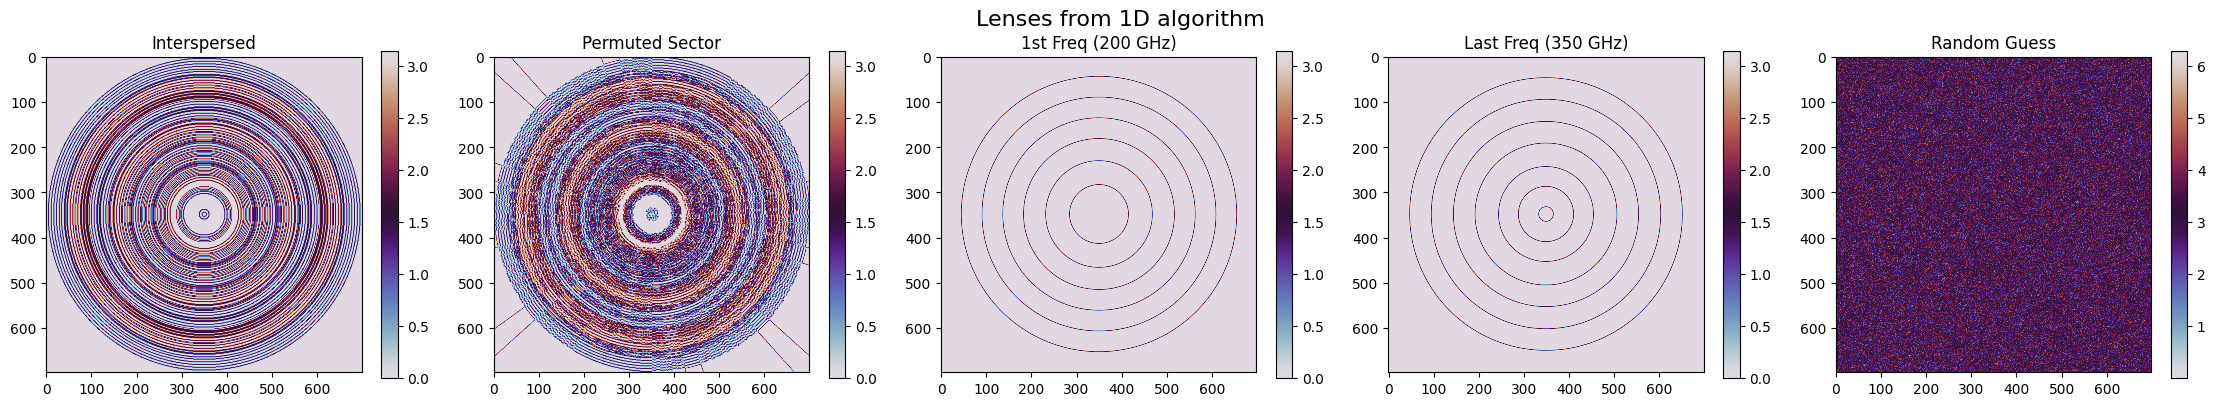

In [7]:

# ---------------------------------------------
# Generate Initial 1D Profiles 
# ---------------------------------------------
print("Generating baseline 1D GS DOEs...")
f0 = 200 * 1e9
does = []
radial_grid = None
for i in range(0, 6, 1):
    f = f0 + i * 30 * 1e9
    initial_doe = []
    params = {
        "fl": 15e-2,  # meters
        "wl": 3e8 / f,  # meters
        "rmax": 10e-2,  # meters
        "N": 350,
        "w0": 0.02,  # meters
        "wgoal": 0.008  # meters
    }
    
    
    DOE_maker = Binary_DOE_1D(params)
    DOE_maker.makeProfiles(p=4)
    DOE_maker.makeDOE(maxiter=150)
    does.append(DOE_maker.getDOE())
    
    if radial_grid is None:
        radial_grid = DOE_maker.r.copy()
# Get specific 2D DOEs for PyTorch Initialization
_, prova1 = create_interspersed_doe(does)
prova1 = prova1[:-1, :-1]  # Crop to 699x699

prova3 = create_permuted_sector_doe(does, 360 / 1440)
prova3 = prova3[:-1, :-1]

does_0_2d = radial_to_2d(
    does[0],
    radial_grid,
    N=350,
    rmax=0.1
)
does_end_2d = radial_to_2d(
    does[-1],
    radial_grid,
    N=350,
    rmax=0.1
)

# --- NEW: Generate Random Phase Lens ---
shape_2d = 2 * params['N'] - 1
random_doe_2d = np.random.uniform(0, 2 * np.pi, size=(shape_2d, shape_2d))

# Lists to iterate for optimization (Added Random Lens)
initial_DOEs = [prova1, prova3, does_0_2d, does_end_2d, random_doe_2d]
titles = ["Interspersed", "Permuted Sector", "1st Freq (200 GHz)", "Last Freq (350 GHz)", "Random Guess"]

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, initial_DOEs, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Lenses from 1D algorithm", fontsize=16)
plt.tight_layout()
plt.show()


2nd part: 2d algorithm to optimize without symetry

Option 2: a more complex Loss function that takes into account the different regions of the plane, so can give more weight to the central region, but also assigns different weights to the average over frequencies and to the worse frequency.

In [33]:

# ==========================================
# PROGRAM 2: PYTORCH MULTI-FREQUENCY BINARY DOE OPTIMIZATION
# FRAUNHOFER PROPAGATION (2D FOURIER TRANSFORM)
# BINARY PHASE STATES: 0 AND PI
# ==========================================

import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn.functional as F

from torch import fft


print("\nStarting 2D Multi-Frequency Binary Optimization...")


# ==========================================
# 1. PARAMETERS
# ==========================================

dx = params['rmax'] / params['N']

shape_2d = 2 * params['N'] - 1

torchoptics.set_default_spacing(dx)

M = shape_2d
center_idx = M // 2

fl = params['fl']
wgoal = params['wgoal']

frequencies = [
    f0 + i * 30e9 for i in range(6)
]

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]

num_frequencies = len(frequencies)


# ==========================================
# 2. BINARY PHASE MODEL
# ==========================================

# Available models:
#
# "physical_relief":
# Phase difference between the two physical
# thicknesses scales with frequency.
#
# "fixed_0_pi":
# The phase states remain exactly 0 and pi
# at every frequency (ideal achromatic model).

binary_phase_model = "fixed_0_pi"


def binary_phase_scale(f):

    if binary_phase_model == "physical_relief":

        return f / f0

    elif binary_phase_model == "fixed_0_pi":

        return 1.0

    else:

        raise ValueError("Unknown binary phase model")


def get_binary_phase(binary_state, f):

    return (
        torch.pi *
        binary_state *
        binary_phase_scale(f)
    )


# ==========================================
# 3. SOURCE PROFILE
# ==========================================

source_profile = gaussian(
    shape_2d,
    waist_radius=params['w0']
).to(device, dtype=torch.float32)

# Incident power at the DOE plane
P_in = torch.sum(
    torch.abs(source_profile)**2
) * dx**2


# ==========================================
# 4. CENTERED FOURIER TRANSFORM
# ==========================================

def centered_fft2(E):

    return fft.fftshift(
        fft.fft2(
            fft.ifftshift(E)
        )
    )


def centered_ifft2(E):

    return fft.fftshift(
        fft.ifft2(
            fft.ifftshift(E)
        )
    )


# ==========================================
# 5. FRAUNHOFER PROPAGATION
# ==========================================

def fraunhofer_forward(E1, f):

    wavelength = 3e8 / f

    # Physical Fourier-transform prefactor
    C = dx**2 / (1j * wavelength * fl)

    # Forward propagation to focal plane
    E2 = C * centered_fft2(E1)

    return E2


def fraunhofer_backward(E2, f):

    wavelength = 3e8 / f

    # Same physical Fourier-transform prefactor
    C = dx**2 / (1j * wavelength * fl)

    # Inverse of the forward propagation operator
    E10 = centered_ifft2(E2 / C)

    return E10


# ==========================================
# 6. FREQUENCY-DEPENDENT FOCAL-PLANE TARGETS
# ==========================================

# DOE-plane spatial frequency coordinates
fx = fft.fftshift(
    fft.fftfreq(
        M,
        d=dx,
        device=device
    )
).to(torch.float32)

fy = fft.fftshift(
    fft.fftfreq(
        M,
        d=dx,
        device=device
    )
).to(torch.float32)

FX, FY = torch.meshgrid(
    fx, fy, indexing='ij'
)


# Store targets, masks and sampling intervals
target_masks = []
target_amplitudes = []
target_intensities = []

center_masks = []
outer_masks = []
background_masks = []

focal_plane_spacings = []

# Regional radii
center_radius = 0.5 * wgoal


for f in frequencies:

    wavelength = 3e8 / f

    # --------------------------------------
    # Physical focal-plane coordinates
    # --------------------------------------

    XF = wavelength * fl * FX
    YF = wavelength * fl * FY

    RF = torch.sqrt(XF**2 + YF**2)

    # Focal-plane pixel spacing
    dxf = wavelength * fl / (M * dx)

    focal_plane_spacings.append(dxf)

    # --------------------------------------
    # Circular uniform target
    # --------------------------------------

    target_mask_f = (
        RF <= wgoal
    ).to(torch.float32)

    # Physical target area (discrete approximation)
    P_tgt = (
        torch.sum(target_mask_f) * dxf**2
    )

    if P_tgt.item() <= 0:
        raise ValueError(
            f"Target contains no pixels at {f/1e9:.1f} GHz. "
            "Increase the sampling resolution."
        )

    # Target amplitude normalized to incident power
    A_tgt_f = (
        target_mask_f *
        torch.sqrt(P_in / P_tgt)
    )

    I_tgt_f = A_tgt_f**2

    target_masks.append(target_mask_f)
    target_amplitudes.append(A_tgt_f)
    target_intensities.append(I_tgt_f)

    # --------------------------------------
    # Regional masks
    # --------------------------------------

    center_masks.append(
        (RF <= center_radius).to(torch.float32)
    )

    outer_masks.append(
        (
            (RF > center_radius) &
            (RF <= wgoal)
        ).to(torch.float32)
    )

    background_masks.append(
        (RF > wgoal).to(torch.float32)
    )


# Keep familiar target variables for compatibility
target_mask = target_masks[0]
A_tgt = target_amplitudes[0]
target_profile = target_mask


# ==========================================
# 7. REGIONAL IMPORTANCE (OPTIONAL)
# ==========================================

# The original binary algorithm optimizes
# target-plane efficiency, not regional MSE.
#
# Therefore, the binary update below follows
# the IFTA sensitivity rule without introducing
# an additional regional loss.


# ==========================================
# 8. OUTPUT STORAGE
# ==========================================

initial_phases = []

optimized_phases = []

optimized_outputs = []
optimized_outputs_2 = []

optimized_freq_outputs = []
optimized_freq_2_outputs = []

# Physical spacing of the common grid used
# for the frequency-averaged output.
output_common_spacing = min(focal_plane_spacings)


# ==========================================
# 9. RESAMPLE INTENSITY TO COMMON GRID
# ==========================================

def resample_to_common_grid(
    intensity,
    source_spacing,
    common_spacing
):

    # Physical coordinates of common grid
    axis = (
        torch.arange(M, device=device, dtype=torch.float32)
        - center_idx
    ) * common_spacing

    X_common, Y_common = torch.meshgrid(
        axis,
        axis,
        indexing='ij'
    )

    # Corresponding pixel indices in source image
    row_idx = center_idx + X_common / source_spacing
    col_idx = center_idx + Y_common / source_spacing

    # grid_sample expects:
    # grid[..., 0] = horizontal (column)
    # grid[..., 1] = vertical (row)

    grid_x = 2 * col_idx / (M - 1) - 1
    grid_y = 2 * row_idx / (M - 1) - 1

    grid = torch.stack(
        (grid_x, grid_y),
        dim=-1
    ).unsqueeze(0)

    intensity_input = intensity.unsqueeze(0).unsqueeze(0)

    resampled = F.grid_sample(
        intensity_input,
        grid,
        mode='bilinear',
        padding_mode='zeros',
        align_corners=True
    )

    return resampled[0, 0]


# ==========================================
# 10. MULTI-FREQUENCY BINARY OPTIMIZATION
# ==========================================

num_iterations = 100

for init_doe, title in zip(initial_DOEs, titles):

    print(f"\nOptimizing Lens: {title}")

    # --------------------------------------
    # Initial DOE phase
    # --------------------------------------

    combined_phase = torch.as_tensor(
        init_doe,
        device=device,
        dtype=torch.float32
    )

    if combined_phase.shape != (M, M):

        raise ValueError(
            f"Incorrect DOE shape: {combined_phase.shape}. "
            f"Expected {(M, M)}."
        )

    # Convert continuous or wrapped initial phase
    # into binary states:
    #
    # state = 0 -> phase 0
    # state = 1 -> phase pi at reference frequency

    binary_state = (
        torch.cos(combined_phase) < 0
    ).to(torch.float32)

    # Reference-frequency binary phase
    phi = torch.pi * binary_state

    # Save initial binary phase
    initial_phases.append(
        phi.detach().cpu().numpy()
    )

    # --------------------------------------
    # Binary IFTA iterations
    # --------------------------------------

    for iteration in range(num_iterations):

        # Accumulated sensitivity across frequencies
        ds_total = torch.zeros_like(
            binary_state,
            dtype=torch.float32
        )

        mean_eff = 0.0

        # ----------------------------------
        # Loop over all frequencies
        # ----------------------------------

        for f_idx, f in enumerate(frequencies):

            dxf = focal_plane_spacings[f_idx]

            mask_f = target_masks[f_idx]
            A_tgt_f = target_amplitudes[f_idx]

            # ----------------------------------
            # 1. Current binary DOE state
            # ----------------------------------

            phi_current = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_current)
            ).to(torch.complex64)

            # ----------------------------------
            # 2. Forward Fraunhofer propagation
            # ----------------------------------

            E2 = fraunhofer_forward(E1, f)

            I_out = torch.abs(E2)**2

            # ----------------------------------
            # 3. Focusing efficiency
            # ----------------------------------

            P_in_target = (
                torch.sum(I_out * mask_f) * dxf**2
            )

            efficiency = P_in_target / P_in

            mean_eff += efficiency.item()

            # ----------------------------------
            # 4. Impose circular target amplitude
            # ----------------------------------

            E20 = (
                A_tgt_f *
                torch.exp(1j * torch.angle(E2))
            )

            # ----------------------------------
            # 5. Backward Fraunhofer propagation
            # ----------------------------------

            E10 = fraunhofer_backward(E20, f)

            # ----------------------------------
            # 6. Calculate sensitivity to toggling
            # ----------------------------------

            # Alternative binary state
            toggled_state = 1.0 - binary_state

            phi_toggled = get_binary_phase(
                toggled_state, f
            )

            E1_toggled = (
                source_profile *
                torch.exp(1j * phi_toggled)
            ).to(torch.complex64)

            # Complex overlap with back-propagated field
            score_current = torch.real(
                torch.conj(E1) * E10
            )

            score_toggled = torch.real(
                torch.conj(E1_toggled) * E10
            )
            """ 
            # Negative sensitivity means that toggling
            # this pixel improves the overlap.
            ds = score_current - score_toggled

            #ds_total += ds
            # Normalize the sensitivity contribution of each frequency
            ds_scale = torch.sqrt(
                torch.mean(ds**2)
            ) + 1e-12
            
            ds_total += ds / ds_scale
            """
            # Calculate benefit of toggling
            gain = score_toggled - score_current
            
            # Normalize the sensitivity magnitude of this frequency
            gain_scale = torch.mean(torch.abs(gain))
            
            gain_normalized = gain / (gain_scale + 1e-12)
            
            # Accumulate normalized contributions
            ds_total += gain_normalized
            
            # Diagnostics
            if iteration == 0:
            
                positive = (gain > 0).sum().item()
                negative = (gain < 0).sum().item()
            
                print(
                    f"  {f/1e9:.0f} GHz | "
                    f"Positive gains: {positive} | "
                    f"Negative gains: {negative} | "
                    f"Mean |gain|: {gain_scale.item():.4e}"
                )

        # ----------------------------------
        # 7. Binary phase update
        # ----------------------------------

        # Toggle pixels where the accumulated
        # sensitivity indicates an improvement.
        """
        toggle_mask = ds_total < 0

        binary_state = torch.where(
            toggle_mask,
            1.0 - binary_state,
            binary_state
        )
        """
        # Inspect the accumulated sensitivity
        positive_total = (ds_total > 0).sum().item()
        negative_total = (ds_total < 0).sum().item()
        
        print(
            f"  Accumulated sensitivity | "
            f"Positive: {positive_total} | "
            f"Negative: {negative_total} | "
            f"Min: {ds_total.min().item():.4e} | "
            f"Max: {ds_total.max().item():.4e}"
        )
        
        # Binary update
        toggle_mask = ds_total > 0
        
        num_toggled = toggle_mask.sum().item()
        
        binary_state = torch.where(
            toggle_mask,
            1.0 - binary_state,
            binary_state
        )
        
        if (iteration + 1) % 10 == 0:
        
            print(
                f"Iteration {iteration+1} | "
                f"Mean efficiency: {mean_eff / num_frequencies:.4f} | "
                f"Changed pixels: {num_toggled}"
            )


    # ======================================
    # 11. STORE OPTIMIZED BINARY DOE
    # ======================================

    optimized_phases.append(
        phi.detach().cpu().numpy()
    )


    # ======================================
    # 12. FINAL INTENSITIES AT ALL FREQUENCIES
    # ======================================

    freq_Is = []

    avg_I = torch.zeros(
        (M, M),
        device=device,
        dtype=torch.float32
    )

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies):

            # Actual binary phase at this frequency
            phi_f = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            # Fraunhofer propagation
            E2 = fraunhofer_forward(E1, f)

            I_f = torch.abs(E2)**2

            # Store original frequency-specific output
            freq_Is.append(
                I_f.cpu().numpy()
            )

            # Resample onto common physical grid
            I_common = resample_to_common_grid(
                I_f,
                focal_plane_spacings[f_idx],
                output_common_spacing
            )

            avg_I += I_common

    # Average over frequencies on common physical grid
    avg_I /= num_frequencies

    optimized_outputs.append(
        avg_I.cpu().numpy()
    )

    optimized_freq_outputs.append(freq_Is)
    
    freq_2_Is = []

    avg_I_2 = torch.zeros(
        (M, M),
        device=device,
        dtype=torch.float32
    )

    with torch.no_grad():

        for f_idx, f in enumerate(frequencies_2):

            # Actual binary phase at this frequency
            phi_f = get_binary_phase(
                binary_state, f
            )

            E1 = (
                source_profile *
                torch.exp(1j * phi_f)
            ).to(torch.complex64)

            # Fraunhofer propagation
            E2 = fraunhofer_forward(E1, f)

            I_f = torch.abs(E2)**2

            # Store original frequency-specific output
            freq_2_Is.append(
                I_f.cpu().numpy()
            )

            # Resample onto common physical grid
            I_common = resample_to_common_grid(
                I_f,
                focal_plane_spacings[f_idx],
                output_common_spacing
            )

            avg_I_2 += I_common

        # Average over frequencies on common physical grid
        avg_I_2 /= num_frequencies

        optimized_outputs_2.append(
            avg_I_2.cpu().numpy()
        )

    optimized_freq_2_outputs.append(freq_2_Is)

print("\nBinary Optimization Complete.")




Starting 2D Multi-Frequency Binary Optimization...

Optimizing Lens: Interspersed
  200 GHz | Positive gains: 204160 | Negative gains: 284441 | Mean |gain|: 4.2334e+01
  230 GHz | Positive gains: 266992 | Negative gains: 221609 | Mean |gain|: 4.0856e+01
  260 GHz | Positive gains: 266224 | Negative gains: 222377 | Mean |gain|: 3.7613e+01
  290 GHz | Positive gains: 258428 | Negative gains: 230173 | Mean |gain|: 3.8322e+01
  320 GHz | Positive gains: 262585 | Negative gains: 226016 | Mean |gain|: 3.9999e+01
  350 GHz | Positive gains: 265314 | Negative gains: 223287 | Mean |gain|: 4.0953e+01
  Accumulated sensitivity | Positive: 266501 | Negative: 222100 | Min: -5.1087e+02 | Max: 5.1094e+02
  Accumulated sensitivity | Positive: 10103 | Negative: 478498 | Min: -5.1126e+02 | Max: 3.7086e+00
  Accumulated sensitivity | Positive: 11633 | Negative: 476968 | Min: -5.1159e+02 | Max: 7.0966e+00
  Accumulated sensitivity | Positive: 19075 | Negative: 469526 | Min: -5.0904e+02 | Max: 1.3356e+01


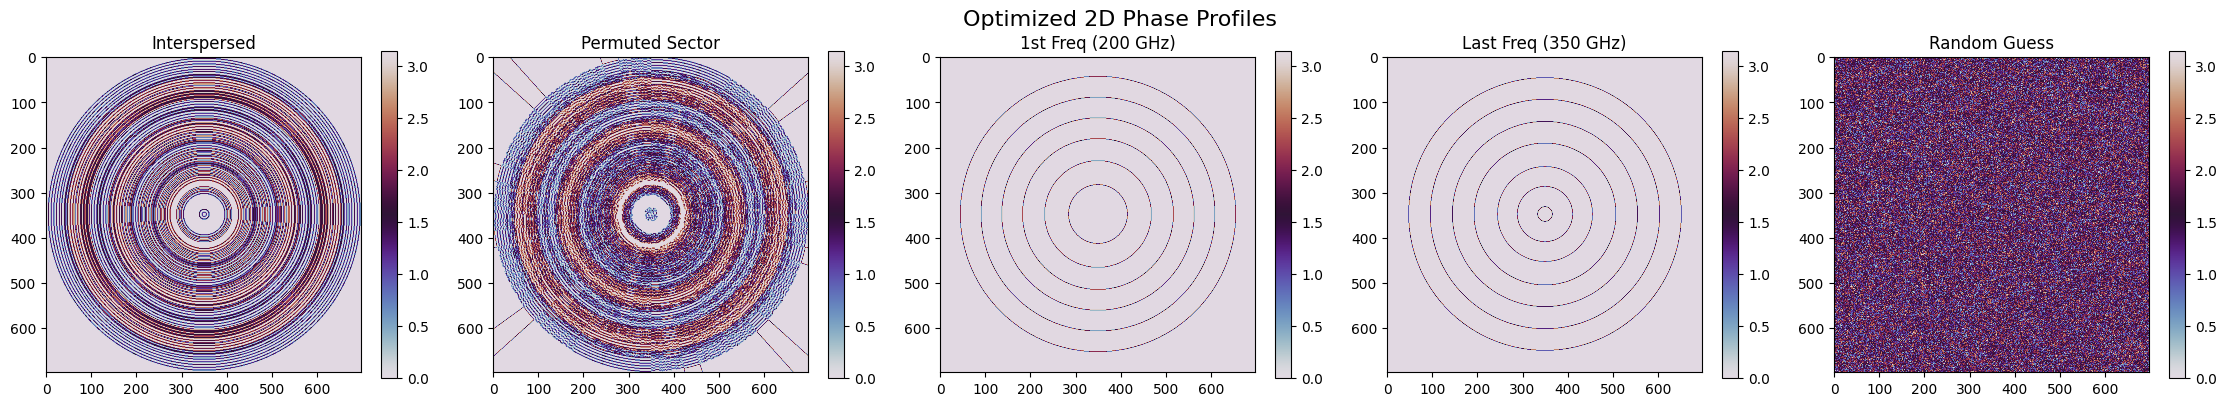

In [34]:
# ==========================================
# PLOTTING RESULTS
# ==========================================

# 1. Plot the Final Optimized Lens Phases (Dynamic width based on number of items)
num_lenses = len(titles)
fig1, axes1 = plt.subplots(1, num_lenses, figsize=(4.5 * num_lenses, 4))
for ax, phase, title in zip(axes1, optimized_phases, titles):
    im = ax.imshow(phase, cmap='twilight')
    ax.set_title(title)
    plt.colorbar(im, ax=ax)
fig1.suptitle("Optimized 2D Phase Profiles", fontsize=16)
plt.tight_layout()
plt.show()


Generating binary DOE cross-section plots...


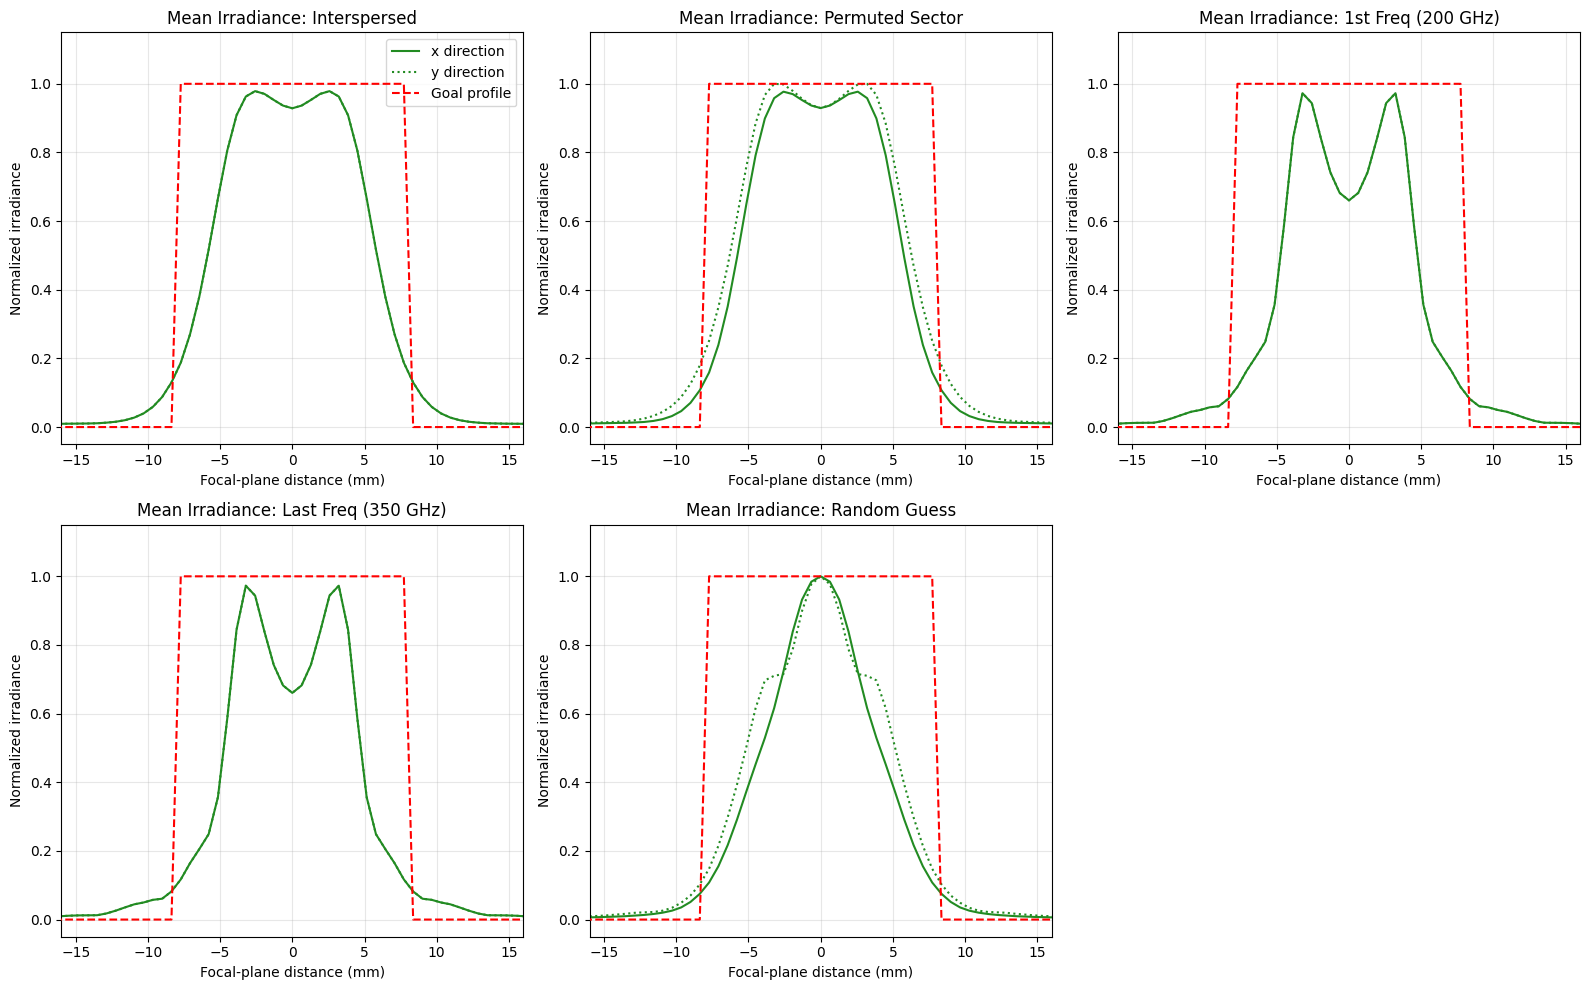

In [35]:

from scipy.ndimage import map_coordinates
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CROSS-SECTION IRRADIANCE:
# BINARY DOE - PHYSICAL FOCAL-PLANE COORDINATES
# ==========================================

print("\nGenerating binary DOE cross-section plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_outputs)

# Recover image size directly from the stored outputs
shape_2d = optimized_freq_outputs[0][0].shape[0]

center_idx = shape_2d // 2

dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Frequencies used in the binary optimization
frequencies = [
    f0 + i * 30e9 for i in range(6)
]


# ==========================================
# 2. Focal-plane sampling
# ==========================================

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return (
        wavelength * params['fl']
        / (shape_2d * dx)
    )


# Calculate focal-plane spacing for each frequency
dxf_values = [
    focal_plane_spacing(f)
    for f in frequencies
]

# Finest physical sampling
dxf_common = min(dxf_values)

# Common physical coordinate grid
x_common = (
    np.arange(shape_2d) - center_idx
) * dxf_common

distance_mm = x_common * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(distance_mm) <= wgoal_mm
).astype(float)


# ==========================================
# 3. Common physical coordinate grid
# ==========================================

X_common, Y_common = np.meshgrid(
    x_common,
    x_common,
    indexing='xy'
)


# ==========================================
# 4. Resample and average each lens
# ==========================================

averaged_physical_outputs = []

fig2, axes2 = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes2 = axes2.flatten()


for lens_idx, title in enumerate(titles):

    freq_Is = optimized_freq_outputs[lens_idx]

    resampled_Is = []

    # --------------------------------------
    # Interpolate every frequency
    # onto the common physical grid
    # --------------------------------------

    for f_idx, f in enumerate(frequencies):

        I_f = np.asarray(freq_Is[f_idx])

        # Original focal-plane pixel spacing
        dxf = focal_plane_spacing(f)

        # Map physical coordinates to source pixel indices
        ix = center_idx + X_common / dxf
        iy = center_idx + Y_common / dxf

        # Bilinear interpolation
        I_resampled = map_coordinates(
            I_f,
            [iy, ix],
            order=1,
            mode='constant',
            cval=0.0
        )

        resampled_Is.append(I_resampled)


    # --------------------------------------
    # Average the six resampled intensities
    # --------------------------------------

    avg_I_common = np.mean(
        resampled_Is,
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_common
    )


    # ======================================
    # 5. Cross-section extraction
    # ======================================

    I_norm = avg_I_common / (
        np.max(avg_I_common) + 1e-12
    )

    # Horizontal and vertical central cuts
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]


    # ======================================
    # 6. Plot
    # ======================================

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile',
        zorder=10
    )

    ax.set_title(
        f"Mean Irradiance: {title}"
    )

    ax.set_xlabel(
        "Focal-plane distance (mm)"
    )

    ax.set_ylabel(
        "Normalized irradiance"
    )

    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(
        -0.05,
        1.15
    )

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# ==========================================
# 7. Disable unused subplot axes
# ==========================================

for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')


plt.tight_layout()
plt.show()



Generating binary DOE cross-section plots...


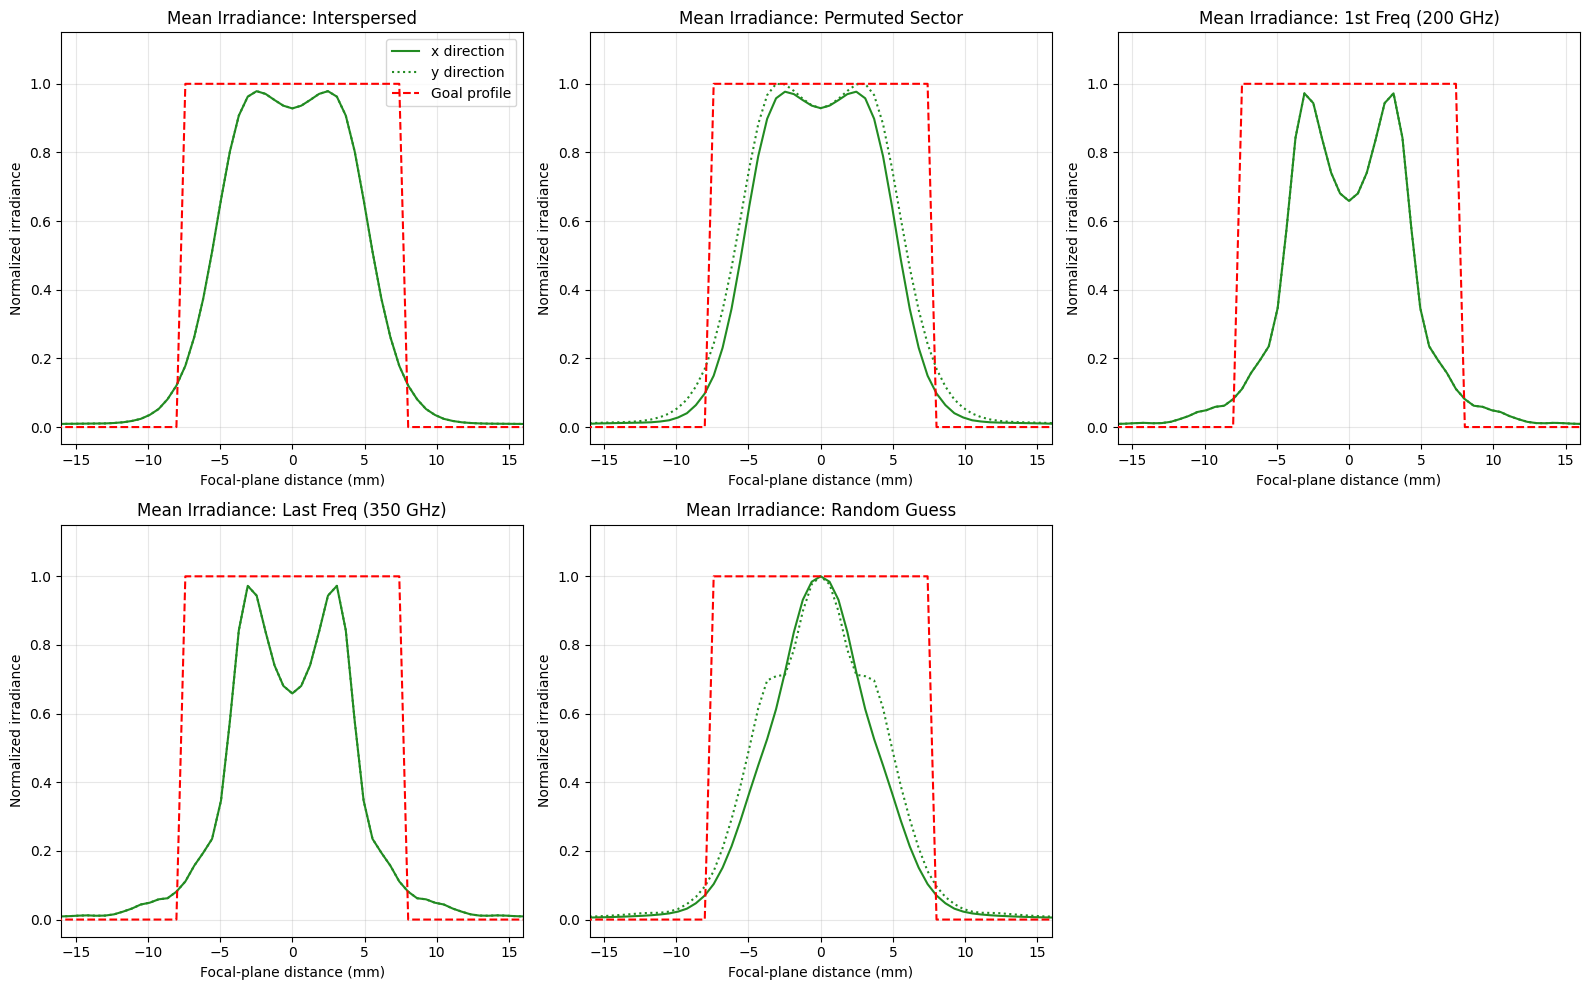

In [36]:

from scipy.ndimage import map_coordinates
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# CROSS-SECTION IRRADIANCE:
# BINARY DOE - PHYSICAL FOCAL-PLANE COORDINATES
# ==========================================

print("\nGenerating binary DOE cross-section plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_2_outputs)

# Recover image size directly from the stored outputs
shape_2d = optimized_freq_2_outputs[0][0].shape[0]

center_idx = shape_2d // 2

dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]


# ==========================================
# 2. Focal-plane sampling
# ==========================================

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return (
        wavelength * params['fl']
        / (shape_2d * dx)
    )


# Calculate focal-plane spacing for each frequency
dxf_values = [
    focal_plane_spacing(f)
    for f in frequencies_2
]

# Finest physical sampling
dxf_common = min(dxf_values)

# Common physical coordinate grid
x_common = (
    np.arange(shape_2d) - center_idx
) * dxf_common

distance_mm = x_common * 1000

# Circular uniform target cross-section
goal_profile = (
    np.abs(distance_mm) <= wgoal_mm
).astype(float)


# ==========================================
# 3. Common physical coordinate grid
# ==========================================

X_common, Y_common = np.meshgrid(
    x_common,
    x_common,
    indexing='xy'
)


# ==========================================
# 4. Resample and average each lens
# ==========================================

averaged_physical_outputs = []

fig2, axes2 = plt.subplots(
    2, 3,
    figsize=(16, 10)
)

axes2 = axes2.flatten()


for lens_idx, title in enumerate(titles):

    freq_Is = optimized_freq_2_outputs[lens_idx]

    resampled_Is = []

    # --------------------------------------
    # Interpolate every frequency
    # onto the common physical grid
    # --------------------------------------

    for f_idx, f in enumerate(frequencies_2):

        I_f = np.asarray(freq_Is[f_idx])

        # Original focal-plane pixel spacing
        dxf = focal_plane_spacing(f)

        # Map physical coordinates to source pixel indices
        ix = center_idx + X_common / dxf
        iy = center_idx + Y_common / dxf

        # Bilinear interpolation
        I_resampled = map_coordinates(
            I_f,
            [iy, ix],
            order=1,
            mode='constant',
            cval=0.0
        )

        resampled_Is.append(I_resampled)


    # --------------------------------------
    # Average the six resampled intensities
    # --------------------------------------

    avg_I_common = np.mean(
        resampled_Is,
        axis=0
    )

    averaged_physical_outputs.append(
        avg_I_common
    )


    # ======================================
    # 5. Cross-section extraction
    # ======================================

    I_norm = avg_I_common / (
        np.max(avg_I_common) + 1e-12
    )

    # Horizontal and vertical central cuts
    x_slice = I_norm[center_idx, :]
    y_slice = I_norm[:, center_idx]


    # ======================================
    # 6. Plot
    # ======================================

    ax = axes2[lens_idx]

    ax.plot(
        distance_mm,
        x_slice,
        color='forestgreen',
        linestyle='-',
        label='x direction'
    )

    ax.plot(
        distance_mm,
        y_slice,
        color='forestgreen',
        linestyle=':',
        label='y direction'
    )

    ax.plot(
        distance_mm,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=1.5,
        label='Goal profile',
        zorder=10
    )

    ax.set_title(
        f"Mean Irradiance: {title}"
    )

    ax.set_xlabel(
        "Focal-plane distance (mm)"
    )

    ax.set_ylabel(
        "Normalized irradiance"
    )

    ax.set_xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    ax.set_ylim(
        -0.05,
        1.15
    )

    ax.grid(alpha=0.3)

    if lens_idx == 0:
        ax.legend(loc='upper right')


# ==========================================
# 7. Disable unused subplot axes
# ==========================================

for j in range(num_lenses, len(axes2)):
    axes2[j].axis('off')


plt.tight_layout()
plt.show()



Generating per-frequency plots...


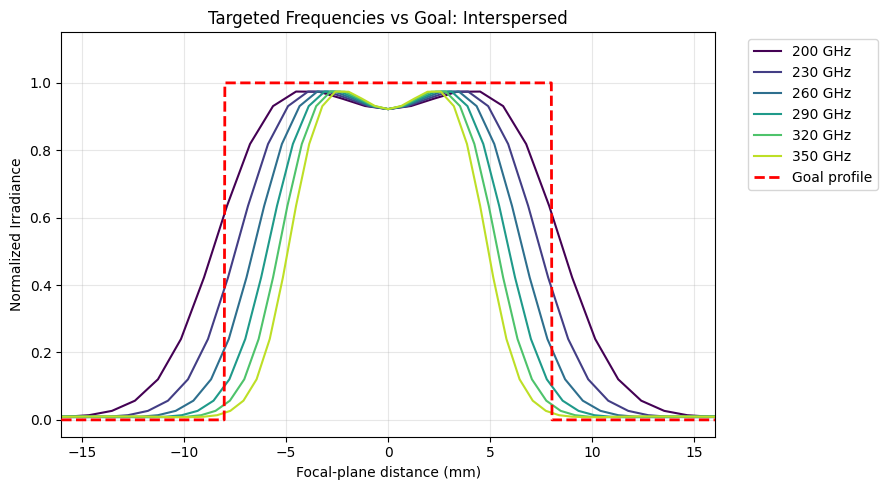

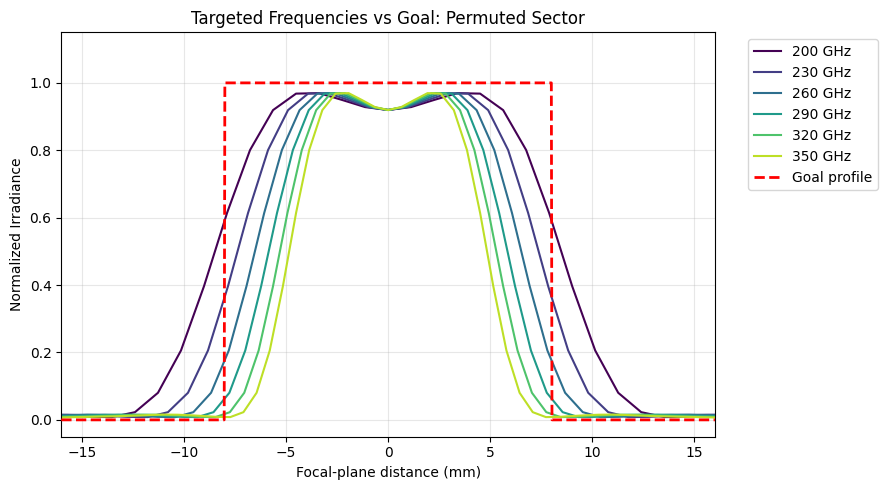

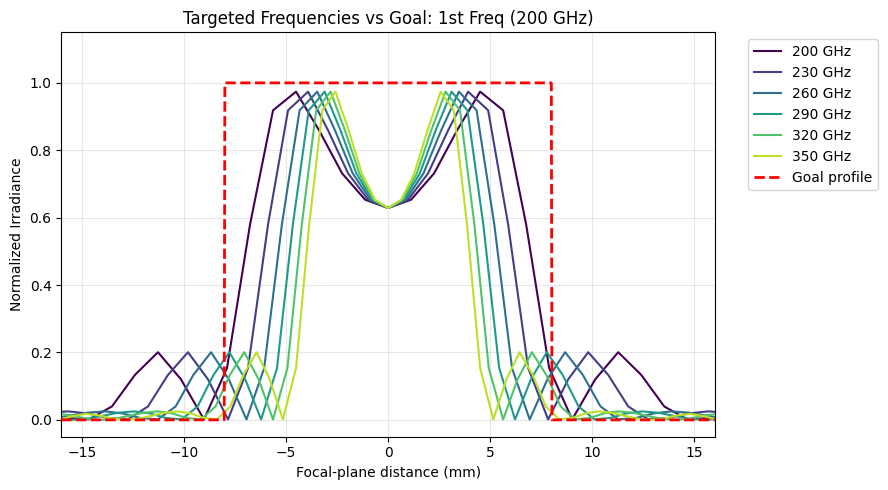

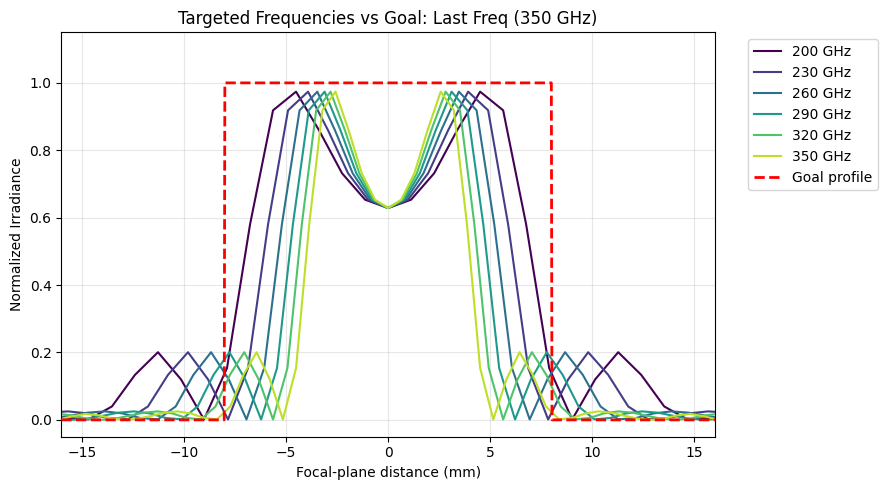

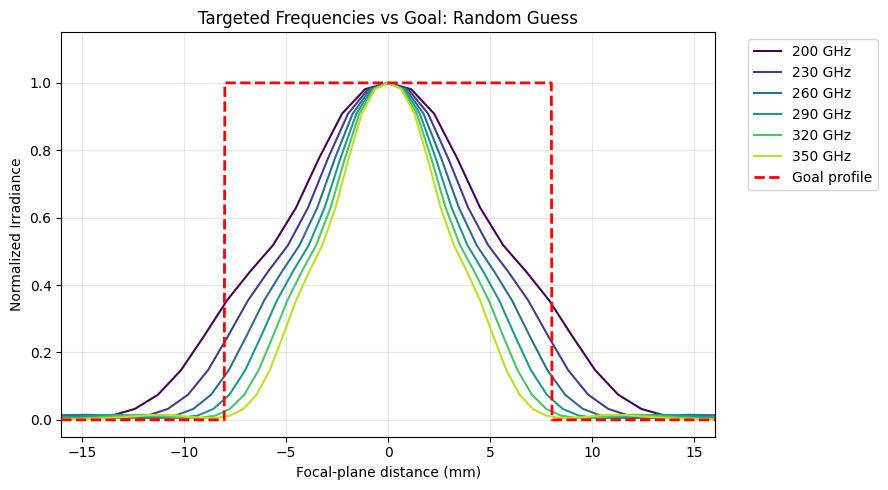

In [37]:

# ==========================================
# PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# BINARY DOE - FRAUNHOFER PROPAGATION
# Physical focal-plane coordinates
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

print("\nGenerating per-frequency plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_outputs)

# Recover output dimensions
shape_2d = optimized_freq_outputs[0][0].shape[0]

center_idx = shape_2d // 2

dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Frequencies used in the binary optimization
frequencies = [
    f0 + i * 30e9 for i in range(6)
]


# ==========================================
# 2. Focal-plane sampling
# ==========================================

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return (
        wavelength * params['fl']
        / (shape_2d * dx)
    )


# ==========================================
# 3. Continuous physical target profile
# ==========================================

# Plot the target independently of the FFT pixel grid.
distance_mm_goal = np.linspace(
    -2 * wgoal_mm,
    2 * wgoal_mm,
    1000
)

goal_profile = (
    np.abs(distance_mm_goal) <= wgoal_mm
).astype(float)


# ==========================================
# 4. Plot each lens
# ==========================================

for lens_idx, (freq_outputs, title) in enumerate(
    zip(optimized_freq_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Distinct color for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies))
    )

    # --------------------------------------
    # Plot each frequency's cross-section
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_outputs, frequencies)
    ):

        freq_I = np.asarray(freq_I)

        # Wavelength
        wavelength = 3e8 / freq_val

        # Correct focal-plane pixel spacing
        dxf = focal_plane_spacing(freq_val)

        # Physical focal-plane coordinates (mm)
        distance_mm_f = (
            np.arange(shape_2d) - center_idx
        ) * dxf * 1000

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central horizontal cross-section
        x_slice = I_norm[center_idx, :]

        # Plot
        plt.plot(
            distance_mm_f,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Plot circular uniform target
    # --------------------------------------

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Focal-plane distance (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()



Generating per-frequency plots...


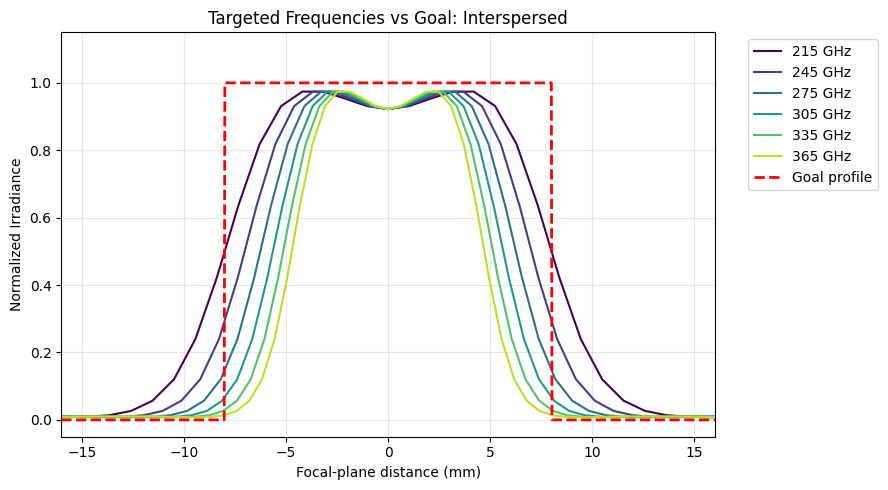

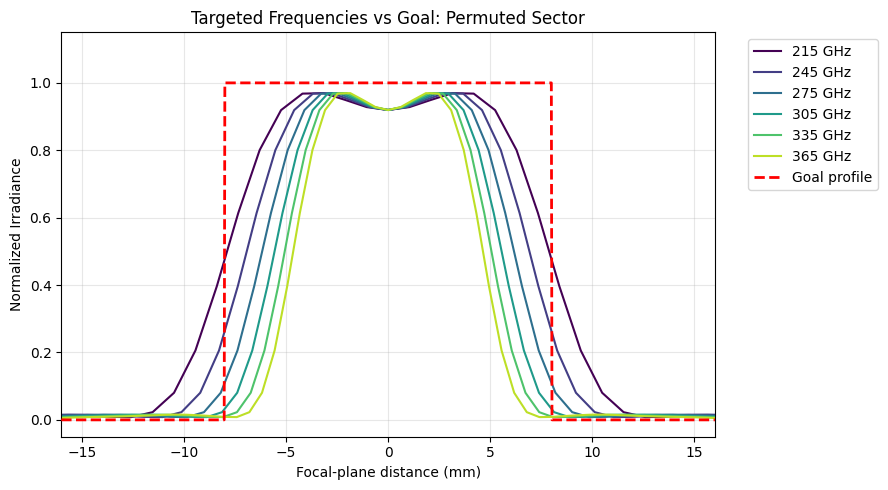

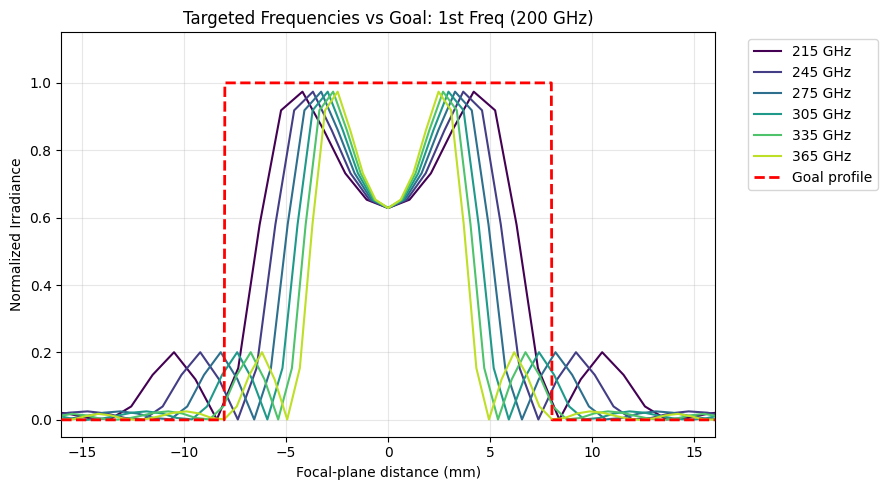

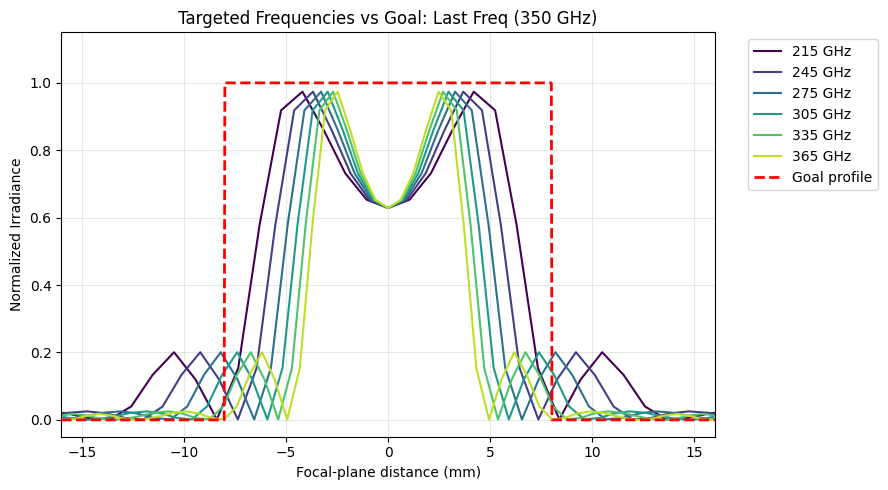

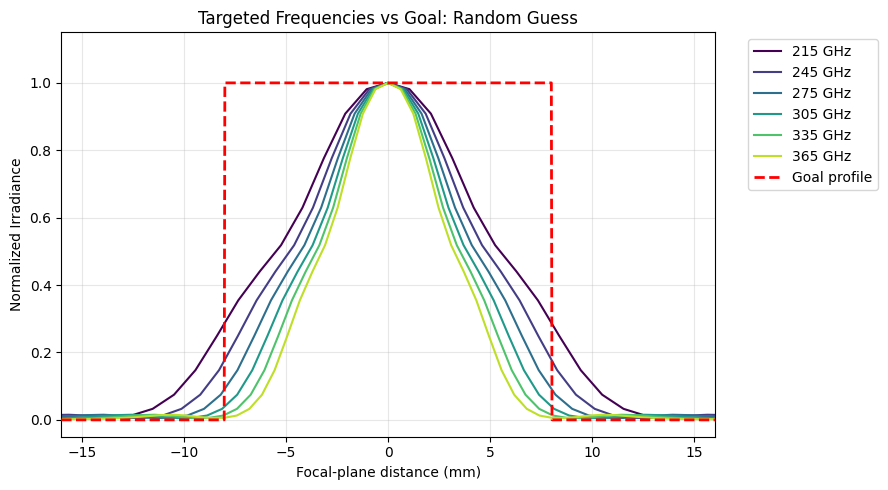

In [38]:

# ==========================================
# PLOT PER-FREQUENCY IRRADIANCES FOR EACH LENS
# BINARY DOE - FRAUNHOFER PROPAGATION
# Physical focal-plane coordinates
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

print("\nGenerating per-frequency plots...")

# ------------------------------------------
# 1. Basic parameters
# ------------------------------------------

num_lenses = len(optimized_freq_2_outputs)

# Recover output dimensions
shape_2d = optimized_freq_2_outputs[0][0].shape[0]

center_idx = shape_2d // 2

dx = params['rmax'] / params['N']

wgoal_mm = params['wgoal'] * 1000

# Second frequency set
frequencies_2 = [
    f0 + 15 * 1e9 + i * 30 * 1e9
    for i in range(6)
]


# ==========================================
# 2. Focal-plane sampling
# ==========================================

def focal_plane_spacing(f):

    wavelength = 3e8 / f

    return (
        wavelength * params['fl']
        / (shape_2d * dx)
    )


# ==========================================
# 3. Continuous physical target profile
# ==========================================

# Plot the target independently of the FFT pixel grid.
distance_mm_goal = np.linspace(
    -2 * wgoal_mm,
    2 * wgoal_mm,
    1000
)

goal_profile = (
    np.abs(distance_mm_goal) <= wgoal_mm
).astype(float)


# ==========================================
# 4. Plot each lens
# ==========================================

for lens_idx, (freq_2_outputs, title) in enumerate(
    zip(optimized_freq_2_outputs, titles)
):

    plt.figure(figsize=(9, 5))

    # Distinct color for each frequency
    colors = plt.cm.viridis(
        np.linspace(0, 0.9, len(frequencies_2))
    )

    # --------------------------------------
    # Plot each frequency's cross-section
    # --------------------------------------

    for f_idx, (freq_I, freq_val) in enumerate(
        zip(freq_2_outputs, frequencies_2)
    ):

        freq_I = np.asarray(freq_I)

        # Wavelength
        wavelength = 3e8 / freq_val

        # Correct focal-plane pixel spacing
        dxf = focal_plane_spacing(freq_val)

        # Physical focal-plane coordinates (mm)
        distance_mm_f = (
            np.arange(shape_2d) - center_idx
        ) * dxf * 1000

        # Normalize each frequency to its own peak
        I_norm = freq_I / (
            np.max(freq_I) + 1e-12
        )

        # Central horizontal cross-section
        x_slice = I_norm[center_idx, :]

        # Plot
        plt.plot(
            distance_mm_f,
            x_slice,
            color=colors[f_idx],
            label=f'{freq_val / 1e9:.0f} GHz'
        )

    # --------------------------------------
    # Plot circular uniform target
    # --------------------------------------

    plt.plot(
        distance_mm_goal,
        goal_profile,
        color='red',
        linestyle='--',
        linewidth=2,
        label='Goal profile',
        zorder=10
    )

    # --------------------------------------
    # Plot configuration
    # --------------------------------------

    plt.title(
        f"Targeted Frequencies vs Goal: {title}"
    )

    plt.xlabel("Focal-plane distance (mm)")
    plt.ylabel("Normalized Irradiance")

    plt.xlim(
        -2 * wgoal_mm,
        2 * wgoal_mm
    )

    plt.ylim(-0.05, 1.15)

    plt.legend(
        bbox_to_anchor=(1.04, 1),
        loc='upper left'
    )

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


In [39]:

# ==========================================
# FOCUSING EFFICIENCY AT EACH FREQUENCY
# ==========================================

print("\nFocusing efficiency per frequency:")

for lens_idx, title in enumerate(titles):

    print(f"\nLens: {title}")

    for f_idx, f in enumerate(frequencies):

        I_f = torch.as_tensor(
            optimized_freq_outputs[lens_idx][f_idx],
            device=device,
            dtype=torch.float32
        )

        dxf = focal_plane_spacings[f_idx]

        # Target power
        P_target = (
            torch.sum(I_f * target_masks[f_idx])
            * dxf**2
        )

        # Background power
        P_background = (
            torch.sum(
                I_f * background_masks[f_idx]
            ) * dxf**2
        )

        efficiency = P_target / P_in

        print(
            f"{f/1e9:.0f} GHz | "
            f"Target efficiency: {efficiency.item():.4f} | "
            f"Background power: {P_background.item()/P_in.item():.4f}"
        )



Focusing efficiency per frequency:

Lens: Interspersed
200 GHz | Target efficiency: 0.6058 | Background power: 0.3942
230 GHz | Target efficiency: 0.7127 | Background power: 0.2873
260 GHz | Target efficiency: 0.7847 | Background power: 0.2153
290 GHz | Target efficiency: 0.8191 | Background power: 0.1809
320 GHz | Target efficiency: 0.8355 | Background power: 0.1645
350 GHz | Target efficiency: 0.8463 | Background power: 0.1537

Lens: Permuted Sector
200 GHz | Target efficiency: 0.6051 | Background power: 0.3949
230 GHz | Target efficiency: 0.7118 | Background power: 0.2882
260 GHz | Target efficiency: 0.7842 | Background power: 0.2158
290 GHz | Target efficiency: 0.8185 | Background power: 0.1815
320 GHz | Target efficiency: 0.8350 | Background power: 0.1650
350 GHz | Target efficiency: 0.8459 | Background power: 0.1541

Lens: 1st Freq (200 GHz)
200 GHz | Target efficiency: 0.7229 | Background power: 0.2771
230 GHz | Target efficiency: 0.7421 | Background power: 0.2579
260 GHz | Tar